# LAB 3 - Supervised Learning

In [ ]:
import pandas as pd
from datetime import date
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.metrics import (
    mean_squared_log_error,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.dates as mdates
import random
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)


# Features

# Predicted Target

# Data Range

In [ ]:
# preprocess the data
# Define feature date range (1 May 2021 - 30 Oct 2021)
start_date = date(2021, 5, 1)
end_date = date(2021, 10, 30)

# -------------------------------------------------------------
# Preprocess Features 1 & 2 (cases_malaysia.csv)
# -------------------------------------------------------------
cases_url = 'https://raw.githubusercontent.com/MoH-Malaysia/covid19-public/main/epidemic/cases_malaysia.csv'
cases_df = pd.read_csv(cases_url, usecols=['date', 'cases_new', 'cases_cluster'], parse_dates=['date'])

mask_cases = (cases_df['date'].dt.date >= start_date) & (cases_df['date'].dt.date <= end_date)
cases_df = cases_df.loc[mask_cases].reset_index(drop=True)

# Fill any missing cluster numbers with 0
cases_df['cases_cluster'] = cases_df['cases_cluster'].fillna(0)

print("--- Group 1: Features 1 & 2 (Cases New & Cases Cluster) ---")
print(cases_df)

--- Group 1: Features 1 & 2 (Cases New & Cases Cluster) ---
          date  cases_new  cases_cluster
0   2021-05-01       2881            873
1   2021-05-02       3418           1084
2   2021-05-03       2500            737
3   2021-05-04       3120            839
4   2021-05-05       3744            743
..         ...        ...            ...
178 2021-10-26       5726            210
179 2021-10-27       6148            200
180 2021-10-28       6377            231
181 2021-10-29       6060            200
182 2021-10-30       5854            274

[183 rows x 3 columns]


In [ ]:
# Define feature date range (1 May 2021 - 30 Oct 2021)
start_date = date(2021, 5, 1)
end_date = date(2021, 10, 30)

# -------------------------------------------------------------
# Feature 3: deaths_malaysia (deaths_new_dod)
# -------------------------------------------------------------
death_url = 'https://raw.githubusercontent.com/MoH-Malaysia/covid19-public/main/epidemic/deaths_malaysia.csv'
death_df = pd.read_csv(death_url, usecols=['date', 'deaths_new_dod'], parse_dates=['date'])
mask_death = (death_df['date'].dt.date >= start_date) & (death_df['date'].dt.date <= end_date)
death_df = death_df.loc[mask_death].reset_index(drop=True)

# -------------------------------------------------------------
# Feature 4: vax_malaysia (daily_partial)
# -------------------------------------------------------------
vax_url = 'https://raw.githubusercontent.com/CITF-Malaysia/citf-public/main/vaccination/vax_malaysia.csv'
vax_df = pd.read_csv(vax_url, usecols=['date', 'daily_partial'], parse_dates=['date'])
mask_vax = (vax_df['date'].dt.date >= start_date) & (vax_df['date'].dt.date <= end_date)
vax_df = vax_df.loc[mask_vax].reset_index(drop=True)

# -------------------------------------------------------------
# Merge Features 3 & 4 side by side on 'date'
# -------------------------------------------------------------
group2_df = pd.merge(death_df, vax_df, on='date', how='inner')

print("--- Group 2: Features 3 & 4 (Deaths New DoD & Daily Partial Vax) ---")
print(group2_df)

--- Group 2: Features 3 & 4 (Deaths New DoD & Daily Partial Vax) ---
          date  deaths_new_dod  daily_partial
0   2021-05-01              16           2932
1   2021-05-02              20           7659
2   2021-05-03              23          24545
3   2021-05-04              14          30142
4   2021-05-05              31          32148
..         ...             ...            ...
178 2021-10-26              55          25204
179 2021-10-27              66          19727
180 2021-10-28              55          19878
181 2021-10-29              59          15612
182 2021-10-30              58           7205

[183 rows x 3 columns]


In [ ]:
# Define feature date range (1 May 2021 - 30 Oct 2021)
start_date = date(2021, 5, 1)
end_date = date(2021, 10, 30)

# -------------------------------------------------------------
# Feature 5: vax_malaysia (daily_full) - National level
# -------------------------------------------------------------
vax_url = 'https://raw.githubusercontent.com/CITF-Malaysia/citf-public/main/vaccination/vax_malaysia.csv'
vax_full_df = pd.read_csv(vax_url, usecols=['date', 'daily_full'], parse_dates=['date'])
mask_vax_full = (vax_full_df['date'].dt.date >= start_date) & (vax_full_df['date'].dt.date <= end_date)
vax_full_df = vax_full_df.loc[mask_vax_full].reset_index(drop=True)

# -------------------------------------------------------------
# Feature 6: hospital.csv (hosp_covid) - Group & Sum State to National
# -------------------------------------------------------------
hosp_url = 'https://raw.githubusercontent.com/MoH-Malaysia/covid19-public/main/epidemic/hospital.csv'
hosp_df = pd.read_csv(hosp_url, usecols=['date', 'hosp_covid'], parse_dates=['date'])
mask_hosp = (hosp_df['date'].dt.date >= start_date) & (hosp_df['date'].dt.date <= end_date)
hosp_df = hosp_df.loc[mask_hosp]

# Sum all states together for each date to get national total
hosp_df = hosp_df.groupby('date', as_index=False)['hosp_covid'].sum()

# -------------------------------------------------------------
# Merge Features 5 & 6 side by side on 'date'
# -------------------------------------------------------------
group3_df = pd.merge(vax_full_df, hosp_df, on='date', how='inner')

print("--- Group 3: Features 5 & 6 (Exactly 183 rows) ---")
print(group3_df)


--- Group 3: Features 5 & 6 (Exactly 183 rows) ---
          date  daily_full  hosp_covid
0   2021-05-01        2575        3099
1   2021-05-02        8122        3250
2   2021-05-03       26751        3409
3   2021-05-04       19708        3438
4   2021-05-05       22915        3698
..         ...         ...         ...
178 2021-10-26      142015        4947
179 2021-10-27      128670        4952
180 2021-10-28      120989        4848
181 2021-10-29       84597        4802
182 2021-10-30       51997        4735

[183 rows x 3 columns]


# Join Data


In [ ]:
# -------------------------------------------------------------------------
# Join All 6 Features Together on 'date'
# -------------------------------------------------------------------------
# Merge datasets sequentially
features_df = pd.merge(cases_df, group2_df, on='date', how='inner')
features_df = pd.merge(features_df, group3_df, on='date', how='inner')

# Set date as index
features_df = features_df.set_index('date')

# -------------------------------------------------------------------------
# Display and Verify Joined Features
# -------------------------------------------------------------------------
print("--- 6 Merged Features Matrix (X) ---")
print(features_df)


--- 6 Merged Features Matrix (X) ---
            cases_new  cases_cluster  deaths_new_dod  daily_partial  \
date                                                                  
2021-05-01       2881            873              16           2932   
2021-05-02       3418           1084              20           7659   
2021-05-03       2500            737              23          24545   
2021-05-04       3120            839              14          30142   
2021-05-05       3744            743              31          32148   
...               ...            ...             ...            ...   
2021-10-26       5726            210              55          25204   
2021-10-27       6148            200              66          19727   
2021-10-28       6377            231              55          19878   
2021-10-29       6060            200              59          15612   
2021-10-30       5854            274              58           7205   

            daily_full  hosp_covid  
da

# Store Data

In [ ]:
# -------------------------------------------------------------------------
# Extract the next-day ICU target and align it by date
# -------------------------------------------------------------------------
target_start = date(2021, 5, 2)
target_end = date(2021, 10, 31)

icu_url = 'https://raw.githubusercontent.com/MoH-Malaysia/covid19-public/main/epidemic/icu.csv'
icu_df = pd.read_csv(
    icu_url,
    usecols=['date', 'icu_covid'],
    parse_dates=['date']
)

mask_icu = (
    (icu_df['date'].dt.date >= target_start)
    &
    (icu_df['date'].dt.date <= target_end)
)

icu_df = icu_df.loc[mask_icu]

# Sum state records to national level.
icu_df = icu_df.groupby(
    'date',
    as_index=False
)['icu_covid'].sum()

# The target for feature date t is ICU usage on date t + 1.
icu_df['feature_date'] = (
    icu_df['date']
    -
    pd.Timedelta(days=1)
)

icu_target_df = (
    icu_df
    .set_index('feature_date')
    [['icu_covid']]
)

features_df.index = pd.to_datetime(features_df.index)

date_df = (
    features_df
    .join(
        icu_target_df,
        how='inner'
    )
)

date_df = date_df.loc[
    (
        date_df.index.date >= start_date
    )
    &
    (
        date_df.index.date <= end_date
    )
].copy()

date_df.index.name = 'date'

expected_dates = pd.date_range(
    start=pd.Timestamp(start_date),
    end=pd.Timestamp(end_date),
    freq='D'
)

if not date_df.index.equals(expected_dates):
    raise ValueError(
        "Feature and target dates are not a complete daily sequence."
    )

print("--- Finalized Clean Dataset with Explicit Next-Day Target ---")
print(date_df)
print("Rows:", len(date_df))


--- Finalized Clean Dataset (date_df) ---
            cases_new  cases_cluster  deaths_new_dod  daily_partial  \
date                                                                  
2021-05-01       2881            873              16           2932   
2021-05-02       3418           1084              20           7659   
2021-05-03       2500            737              23          24545   
2021-05-04       3120            839              14          30142   
2021-05-05       3744            743              31          32148   
...               ...            ...             ...            ...   
2021-10-26       5726            210              55          25204   
2021-10-27       6148            200              66          19727   
2021-10-28       6377            231              55          19878   
2021-10-29       6060            200              59          15612   
2021-10-30       5854            274              58           7205   

            daily_full  hosp_covid

# Split data into X Column (Features) and Y Column (Target)


In [ ]:
# Define target column name
y_col = 'icu_covid'

# Separate into X (Features) and y (Target)
if y_col in date_df.columns:
    feature_cols = [col for col in date_df.columns if col != y_col]
    X_data = date_df[feature_cols]
    y_data = date_df[y_col]

    print("--- X_data (6 Features) ---")
    print(X_data.head())
    print("X shape:", X_data.shape)

    print("\n--- y_data (Target: icu_covid) ---")
    print(y_data.head())
    print("y shape:", y_data.shape)
else:
    print(f"'{y_col}' column not found in date_df.")

--- X_data (6 Features) ---
            cases_new  cases_cluster  deaths_new_dod  daily_partial  \
date                                                                  
2021-05-01       2881            873              16           2932   
2021-05-02       3418           1084              20           7659   
2021-05-03       2500            737              23          24545   
2021-05-04       3120            839              14          30142   
2021-05-05       3744            743              31          32148   

            daily_full  hosp_covid  
date                                
2021-05-01        2575        3099  
2021-05-02        8122        3250  
2021-05-03       26751        3409  
2021-05-04       19708        3438  
2021-05-05       22915        3698  
X shape: (183, 6)

--- y_data (Target: icu_covid) ---
date
2021-05-01    442
2021-05-02    452
2021-05-03    442
2021-05-04    453
2021-05-05    497
Name: icu_covid, dtype: int64
y shape: (183,)


# Feature Scalling

In [ ]:
# Keep raw features until after the chronological split.
# The scaler is fitted later using training data only.
y = y_data.copy()
X_data = X_data.copy()

print("--- Raw Features Matrix (X_data) ---")
print(X_data.head())

print("--- Target Variable (y) ---")
print(y.head())


--- Scaled Features Matrix (X_scaled) ---
            cases_new  cases_cluster  deaths_new_dod  daily_partial  \
date                                                                  
2021-05-01  -1.362426      -0.908836       -1.417480      -1.451213   
2021-05-02  -1.274960      -0.660602       -1.375348      -1.399145   
2021-05-03  -1.424483      -1.068836       -1.343749      -1.213147   
2021-05-04  -1.323498      -0.948836       -1.438547      -1.151497   
2021-05-05  -1.221861      -1.061777       -1.259484      -1.129401   
...               ...            ...             ...            ...   
2021-10-26  -0.899034      -1.688834       -1.006689      -1.205888   
2021-10-27  -0.830299      -1.700598       -0.890825      -1.266217   
2021-10-28  -0.793000      -1.664128       -1.006689      -1.264554   
2021-10-29  -0.844632      -1.700598       -0.964557      -1.311543   
2021-10-30  -0.878186      -1.613540       -0.975090      -1.404146   

            daily_full  hosp_covid

Primary forecasting evaluation uses chronological data. Shuffled results are secondary sensitivity analysis only.\n\n# Split data into training, testing and validation set

In [ ]:
# -------------------------------------------------------------------------
# Chronological train / validation / test split
# -------------------------------------------------------------------------
train_end = int(len(X_data) * 0.70)
validation_end = int(len(X_data) * 0.85)

X_train_raw = X_data.iloc[:train_end].copy()
X_val_raw = X_data.iloc[train_end:validation_end].copy()
X_test_raw = X_data.iloc[validation_end:].copy()

y_train = y.iloc[:train_end].copy()
y_val = y.iloc[train_end:validation_end].copy()
y_test = y.iloc[validation_end:].copy()

# Fit preprocessing on training data only.
scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_val = pd.DataFrame(
    scaler.transform(X_val_raw),
    columns=X_val_raw.columns,
    index=X_val_raw.index
)

X_test = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print("--- 70% Training Set ---")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\n--- 15% Validation Set ---")
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("\n--- 15% Testing Set ---")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# Simple persistence baseline:
# predict tomorrow's ICU value using today's observed ICU value.
baseline_target = y.shift(1)
baseline_test_pred = baseline_target.loc[y_test.index]

baseline_mae = mean_absolute_error(
    y_test,
    baseline_test_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_test_pred
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_test_pred
)

print("\n--- Previous-Day ICU Baseline ---")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²:", baseline_r2)


--- 70% Training Set (128 days) ---
X_train shape: (128, 6)
y_train shape: (128,)

--- 15% Validation Set (27 days) ---
X_val shape: (27, 6)
y_val shape: (27,)

--- 15% Testing Set (28 days) ---
X_test shape: (28, 6)
y_test shape: (28,)


# Lasso Regression

## Unshuffled Lasso Regression

In [ ]:
# 1. Initialize and train Lasso model
lasso_unshuffled = Lasso(alpha=0.1, random_state=42)
lasso_unshuffled.fit(X_train, y_train)

# 2. Predict on Train, Validation, and Test sets
y_train_pred_unshuf = np.clip(lasso_unshuffled.predict(X_train), 0, None)
y_val_pred_unshuf   = np.clip(lasso_unshuffled.predict(X_val), 0, None)
y_test_pred_unshuf  = np.clip(lasso_unshuffled.predict(X_test), 0, None)

# 3. Calculate MSLE and R² for Unshuffled
msle_train_unshuf = mean_squared_log_error(y_train, y_train_pred_unshuf)
msle_val_unshuf   = mean_squared_log_error(y_val, y_val_pred_unshuf)
msle_test_unshuf  = mean_squared_log_error(y_test, y_test_pred_unshuf)
r2_unshuf         = r2_score(y_test, y_test_pred_unshuf)

print("\n================= [UNSHUFFLED] RESULTS =================")
print(f"MSLE Train:      {msle_train_unshuf:.6f}")
print(f"MSLE Test:       {msle_test_unshuf:.6f}")
print(f"MSLE Validation: {msle_val_unshuf:.6f}")
print(f"R²:   {r2_unshuf:.6f}")


================= [UNSHUFFLED] RESULTS =================
MSLE Train:      0.006570
MSLE Test:       0.006279
MSLE Validation: 0.007579
Accuracy (R²):   0.720378


Primary forecasting evaluation uses chronological data. Shuffled results are secondary sensitivity analysis only.\n\n## Shuffled Lasso Regression

In [ ]:
# Split raw data randomly for secondary sensitivity analysis.
X_train_shuf_raw, X_temp_shuf_raw, y_train_shuf, y_temp_shuf = train_test_split(
    X_data,
    y,
    test_size=0.30,
    shuffle=True,
    random_state=42
)

X_val_shuf_raw, X_test_shuf_raw, y_val_shuf, y_test_shuf = train_test_split(
    X_temp_shuf_raw,
    y_temp_shuf,
    test_size=0.50,
    shuffle=True,
    random_state=42
)

scaler_shuf = StandardScaler()

X_train_shuf = pd.DataFrame(
    scaler_shuf.fit_transform(X_train_shuf_raw),
    columns=X_train_shuf_raw.columns,
    index=X_train_shuf_raw.index
)

X_val_shuf = pd.DataFrame(
    scaler_shuf.transform(X_val_shuf_raw),
    columns=X_val_shuf_raw.columns,
    index=X_val_shuf_raw.index
)

X_test_shuf = pd.DataFrame(
    scaler_shuf.transform(X_test_shuf_raw),
    columns=X_test_shuf_raw.columns,
    index=X_test_shuf_raw.index
)

print("Training set:", X_train_shuf.shape)
print("Validation set:", X_val_shuf.shape)
print("Testing set:", X_test_shuf.shape)

# Shuffled results are secondary sensitivity analysis only.
lasso_shuffled = Lasso(alpha=0.1, random_state=42)
lasso_shuffled.fit(X_train_shuf, y_train_shuf)

y_train_pred_shuf = np.clip(
    lasso_shuffled.predict(X_train_shuf),
    0,
    None
)

y_val_pred_shuf = np.clip(
    lasso_shuffled.predict(X_val_shuf),
    0,
    None
)

y_test_pred_shuf = np.clip(
    lasso_shuffled.predict(X_test_shuf),
    0,
    None
)

msle_train_shuf = mean_squared_log_error(
    y_train_shuf,
    y_train_pred_shuf
)

msle_val_shuf = mean_squared_log_error(
    y_val_shuf,
    y_val_pred_shuf
)

msle_test_shuf = mean_squared_log_error(
    y_test_shuf,
    y_test_pred_shuf
)

r2_shuf = r2_score(
    y_test_shuf,
    y_test_pred_shuf
)

print("================== [SHUFFLED SENSITIVITY] RESULTS ==================")
print(f"MSLE Train:      {msle_train_shuf:.6f}")
print(f"MSLE Test:       {msle_test_shuf:.6f}")
print(f"MSLE Validation: {msle_val_shuf:.6f}")
print(f"R²:              {r2_shuf:.6f}")


================== [SHUFFLED] RESULTS ==================
MSLE Train:      0.006299
MSLE Test:       0.008313
MSLE Validation: 0.004498
Accuracy (R²):   0.920795


## Shuffled Scatter Plot （Predictions vs Ground Truth）

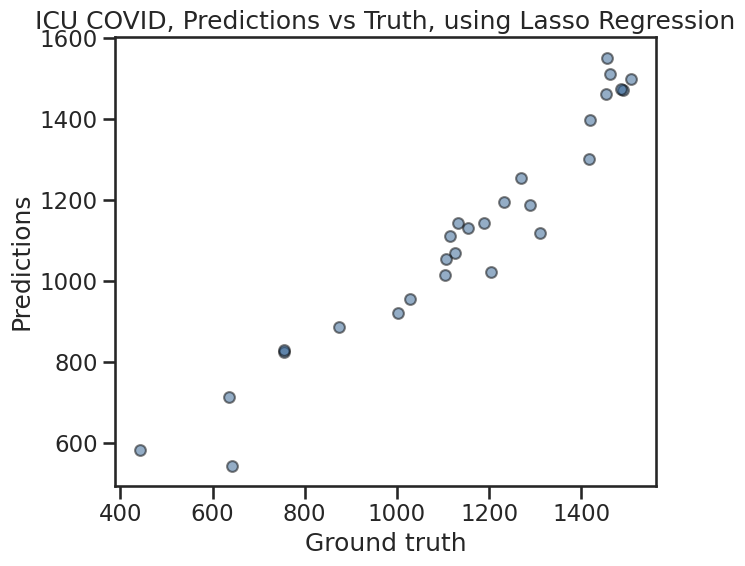

In [ ]:
sns.set_context('talk')
sns.set_style('ticks')
sns.set_palette('dark')

plt.figure(figsize=(7, 6))
ax = plt.axes()
ax.scatter(y_test_shuf, y_test_pred_shuf, alpha=0.5, color='#2b5c8f', edgecolors='k', s=60)

ax.set(
    xlabel='Ground truth',
    ylabel='Predictions',
    title='ICU COVID, Predictions vs Truth, using Lasso Regression'
)
plt.tight_layout()
plt.show()

## Unshuffled Scatter Plot （Actual vs Predicted）

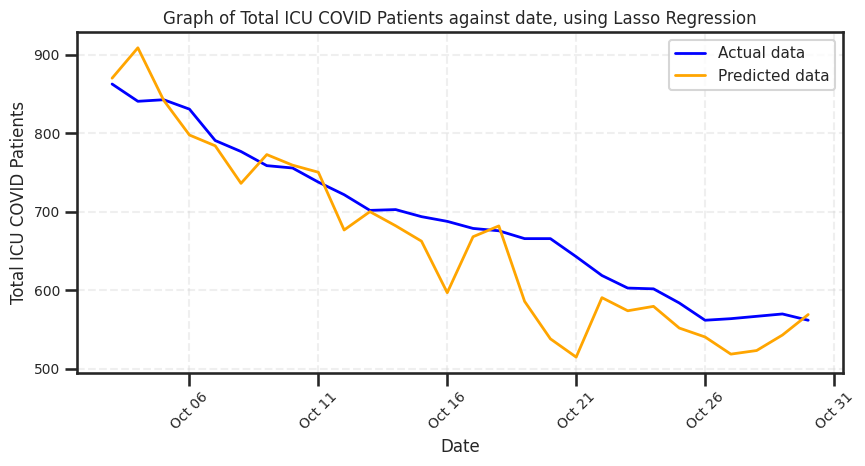

In [ ]:
plt.figure(figsize=(9, 5))
ax = plt.axes()

test_dates = y_test.index
ax.plot(test_dates, y_test.values, label='Actual data', color='blue', linewidth=2)
ax.plot(test_dates, y_test_pred_unshuf, label='Predicted data', color='orange', linewidth=2)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Total ICU COVID Patients', fontsize=12)
ax.set_title('Graph of Total ICU COVID Patients against date, using Lasso Regression', fontsize=12)
ax.legend(loc='upper right', fontsize=11)

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Linear Regression

## Unshuffled linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression

# 1. Initialize and train Linear Regression model
lr_unshuffled = LinearRegression()
lr_unshuffled.fit(X_train, y_train)

# 2. Predict on Train, Validation, and Test sets
y_train_pred_lr_unshuf = np.clip(lr_unshuffled.predict(X_train), 0, None)
y_val_pred_lr_unshuf   = np.clip(lr_unshuffled.predict(X_val), 0, None)
y_test_pred_lr_unshuf  = np.clip(lr_unshuffled.predict(X_test), 0, None)

# 3. Calculate MSLE and R² for Unshuffled
msle_train_lr_unshuf = mean_squared_log_error(y_train, y_train_pred_lr_unshuf)
msle_val_lr_unshuf   = mean_squared_log_error(y_val, y_val_pred_lr_unshuf)
msle_test_lr_unshuf  = mean_squared_log_error(y_test, y_test_pred_lr_unshuf)
r2_lr_unshuf         = r2_score(y_test, y_test_pred_lr_unshuf)

print("\n================= [UNSHUFFLED LINEAR REGRESSION] RESULTS =================")
print(f"MSLE Train:      {msle_train_lr_unshuf:.6f}")
print(f"MSLE Test:       {msle_test_lr_unshuf:.6f}")
print(f"MSLE Validation: {msle_val_lr_unshuf:.6f}")
print(f"R²:   {r2_lr_unshuf:.6f}")


================= [UNSHUFFLED LINEAR REGRESSION] RESULTS =================
MSLE Train:      0.006479
MSLE Test:       0.006802
MSLE Validation: 0.007902
Accuracy (R²):   0.699962


## UnShuffled linear Regression scatter plot (Actuall vs Predicted)

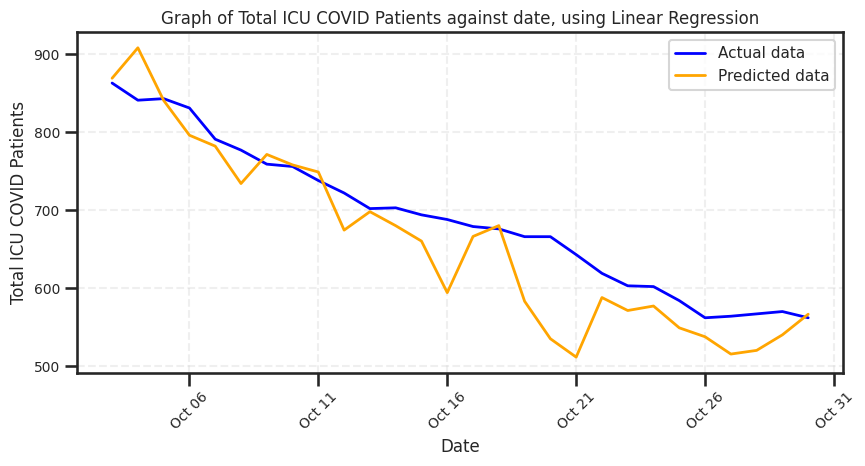

In [ ]:
plt.figure(figsize=(9, 5))
ax = plt.axes()

test_dates = y_test.index
ax.plot(test_dates, y_test.values, label='Actual data', color='blue', linewidth=2)
ax.plot(test_dates, y_test_pred_lr_unshuf, label='Predicted data', color='orange', linewidth=2)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Total ICU COVID Patients', fontsize=12)
ax.set_title('Graph of Total ICU COVID Patients against date, using Linear Regression', fontsize=12)
ax.legend(loc='upper right', fontsize=11)

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Primary forecasting evaluation uses chronological data. Shuffled results are secondary sensitivity analysis only.\n\n## Shuffled Linear Regrssion

In [ ]:
from sklearn.linear_model import LinearRegression

# Shuffled results are secondary sensitivity analysis only.
lr_shuffled = LinearRegression()
lr_shuffled.fit(X_train_shuf, y_train_shuf)

y_train_pred_lr_shuf = np.clip(
    lr_shuffled.predict(X_train_shuf),
    0,
    None
)

y_val_pred_lr_shuf = np.clip(
    lr_shuffled.predict(X_val_shuf),
    0,
    None
)

y_test_pred_lr_shuf = np.clip(
    lr_shuffled.predict(X_test_shuf),
    0,
    None
)

msle_train_lr_shuf = mean_squared_log_error(
    y_train_shuf,
    y_train_pred_lr_shuf
)

msle_val_lr_shuf = mean_squared_log_error(
    y_val_shuf,
    y_val_pred_lr_shuf
)

msle_test_lr_shuf = mean_squared_log_error(
    y_test_shuf,
    y_test_pred_lr_shuf
)

r2_lr_shuf = r2_score(
    y_test_shuf,
    y_test_pred_lr_shuf
)

print("\n================== [SHUFFLED LINEAR SENSITIVITY] RESULTS ==================")
print(f"MSLE Train:      {msle_train_lr_shuf:.6f}")
print(f"MSLE Test:       {msle_test_lr_shuf:.6f}")
print(f"MSLE Validation: {msle_val_lr_shuf:.6f}")
print(f"R²:              {r2_lr_shuf:.6f}")



================== [SHUFFLED LINEAR REGRESSION] RESULTS ==================
MSLE Train:      0.006255
MSLE Test:       0.008340
MSLE Validation: 0.004495
Accuracy (R²):   0.920195


## Shuffled linear Regression scatter plot (Prediction Vs Gound Truth)

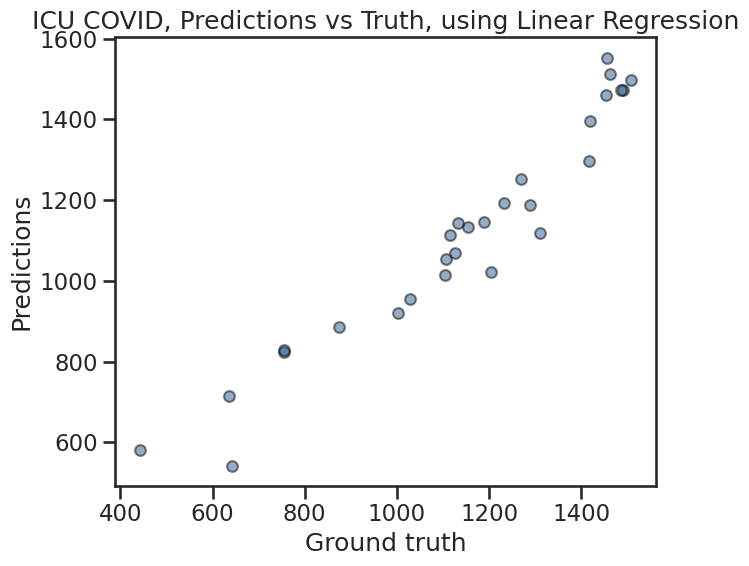

In [ ]:
sns.set_context('talk')
sns.set_style('ticks')
sns.set_palette('dark')

plt.figure(figsize=(7, 6))
ax = plt.axes()
ax.scatter(y_test_shuf, y_test_pred_lr_shuf, alpha=0.5, color='#2b5c8f', edgecolors='k', s=60)

ax.set(
    xlabel='Ground truth',
    ylabel='Predictions',
    title='ICU COVID, Predictions vs Truth, using Linear Regression'
)
plt.tight_layout()
plt.show()

# ANN Regression

## Unshuffled ANN Method

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import MeanSquaredLogarithmicError

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_log_error, r2_score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Form an ANN model with 3 hidden layers

In [ ]:
# Set learning rate
learning_rate = 0.01

# Create ANN model with 3 hidden layers
ann = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation='relu'),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),

    Dense(1, activation='linear')
])

## Loss Function and Train the Model

In [ ]:
# Define MSLE loss function
msle = MeanSquaredLogarithmicError()

# Compile the ANN model
ann.compile(
    loss=msle,
    optimizer=Adam(learning_rate=learning_rate),
    metrics=[msle]
)

# Train the ANN model
history = ann.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=2
)

Epoch 1/20
4/4 - 2s - 478ms/step - loss: 27.9588 - mean_squared_logarithmic_error: 27.9588 - val_loss: 11.6215 - val_mean_squared_logarithmic_error: 11.6215
Epoch 2/20
4/4 - 0s - 25ms/step - loss: 3.9370 - mean_squared_logarithmic_error: 3.9370 - val_loss: 2.8734 - val_mean_squared_logarithmic_error: 2.8734
Epoch 3/20
4/4 - 0s - 24ms/step - loss: 0.4638 - mean_squared_logarithmic_error: 0.4638 - val_loss: 0.6919 - val_mean_squared_logarithmic_error: 0.6919
Epoch 4/20
4/4 - 0s - 23ms/step - loss: 0.3693 - mean_squared_logarithmic_error: 0.3693 - val_loss: 0.2130 - val_mean_squared_logarithmic_error: 0.2130
Epoch 5/20
4/4 - 0s - 23ms/step - loss: 0.7899 - mean_squared_logarithmic_error: 0.7899 - val_loss: 0.1542 - val_mean_squared_logarithmic_error: 0.1542
Epoch 6/20
4/4 - 0s - 23ms/step - loss: 1.0450 - mean_squared_logarithmic_error: 1.0450 - val_loss: 0.1641 - val_mean_squared_logarithmic_error: 0.1641
Epoch 7/20
4/4 - 0s - 24ms/step - loss: 1.0424 - mean_squared_logarithmic_error: 1.

## Graph of MSLE and Validation MSLE

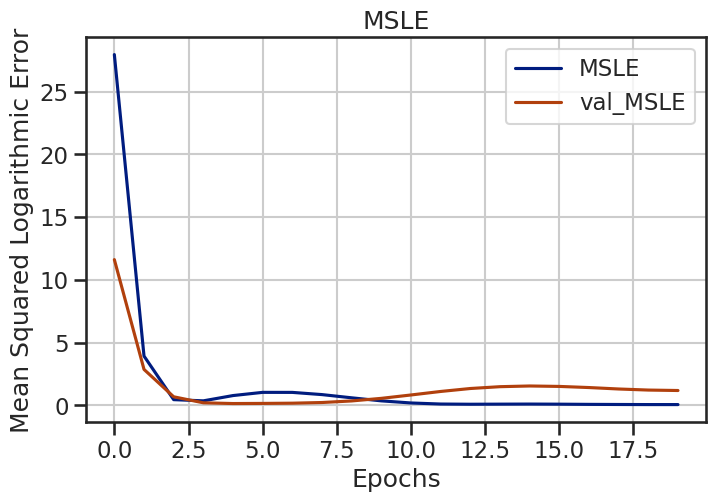

In [ ]:
# Plot MSLE and validation MSLE

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['mean_squared_logarithmic_error'],
    label='MSLE'
)

plt.plot(
    history.history['val_mean_squared_logarithmic_error'],
    label='val_MSLE'
)

plt.title('MSLE')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Logarithmic Error')
plt.legend(loc='upper right')
plt.grid(True)

plt.show()

## Graph of Actual Data and Predicted Data Against Date

In [ ]:
# Make predictions using the Unshuffled ANN model
y_test_pred = ann.predict(X_test, verbose=0).flatten()

# MSLE requires non-negative predictions
y_test_pred = np.clip(y_test_pred, 0, None)

print("Actual values:", len(y_test))
print("Predicted values:", len(y_test_pred))
print("Test dates:", len(test_dates))

Actual values: 28
Predicted values: 28
Test dates: 28


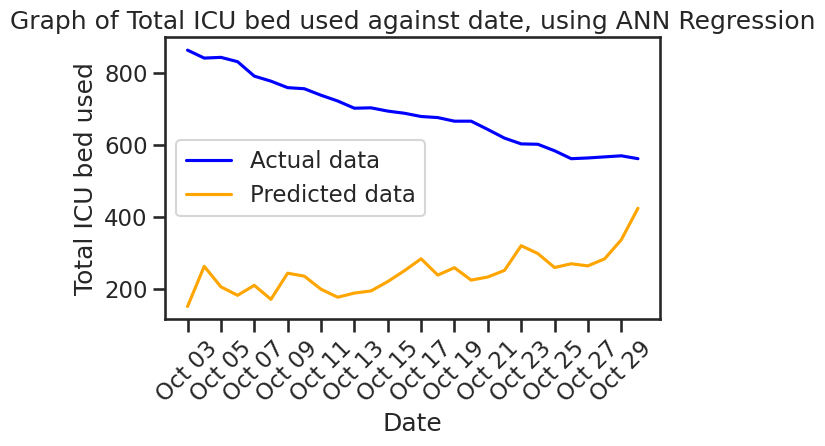

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter

sns.set_context('talk')
sns.set_style('ticks')
sns.set_palette('dark')

ax = plt.axes()

ax.plot(test_dates, y_test, label='Actual data', color='blue')
ax.plot(test_dates, y_test_pred, label='Predicted data', color='orange')

num_labels = 10
step = len(test_dates) // num_labels
selected_dates = test_dates[::step]

ax.set_xticks(selected_dates)
ax.xaxis.set_major_formatter(DateFormatter('%b %d'))

ax.set(
    xlabel='Date',
    ylabel='Total ICU bed used',
    title='Graph of Total ICU bed used against date, using ANN Regression'
)

ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Graph of Predictions and Ground Truth

In [ ]:
# Make predictions using the trained ANN model

y_test_pred = ann.predict(
    X_test,
    verbose=0
).flatten()

# ICU bed usage cannot be negative
y_test_pred = np.clip(
    y_test_pred,
    0,
    None
)

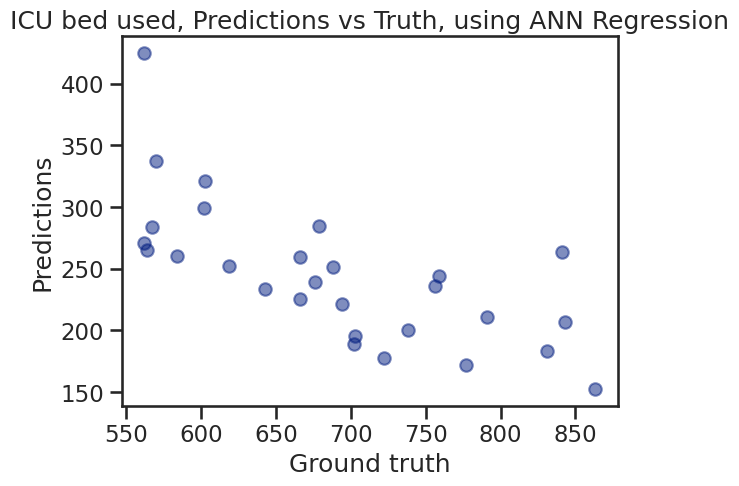

In [ ]:
# Plot Predictions vs Ground Truth

sns.set_context('talk')
sns.set_style('ticks')
sns.set_palette('dark')

ax = plt.axes()

ax.scatter(
    y_test,
    y_test_pred,
    alpha=0.5
)

ax.set(
    xlabel='Ground truth',
    ylabel='Predictions',
    title='ICU bed used, Predictions vs Truth, using ANN Regression'
)

plt.show()

## Evaluate ANN Model

In [ ]:
# Calculate MSLE for training and testing data

train_pred = ann.predict(
    X_train,
    verbose=0
).flatten()

train_pred = np.clip(
    train_pred,
    0,
    None
)

test_pred = np.clip(
    y_test_pred,
    0,
    None
)

error_df = pd.DataFrame({
    'train': [
        mean_squared_log_error(
            y_train,
            train_pred
        )
    ],
    'test': [
        mean_squared_log_error(
            y_test,
            test_pred
        )
    ]
})

error_df

,train,test
0,0.069284,1.202134


In [ ]:
# Calculate MSLE for validation data

val_pred = ann.predict(
    X_val,
    verbose=0
).flatten()

val_pred = np.clip(
    val_pred,
    0,
    None
)

validation_msle = mean_squared_log_error(
    y_val,
    val_pred
)

print("Unshuffled Validation MSLE:", validation_msle)

Unshuffled Validation MSLE: 1.1922799348831177


In [ ]:
# Store error values
error_df = list()

# Calculate MSLE for training and testing data
error_df.append(
    pd.Series({
        'train': mean_squared_log_error(
            y_train,
            np.clip(
                ann.predict(X_train, verbose=0).flatten(),
                0,
                None
            )
        ),

        'test': mean_squared_log_error(
            y_test,
            y_test_pred
        )
    },
    name='mean sq log error')
)

error_df = pd.concat(error_df, axis=1)

error_df

,mean sq log error
train,0.069284
test,1.202134


## Test Accuracy

In [ ]:
# Calculate R² for the test set

r2 = r2_score(
    y_test,
    y_test_pred
)

print("R^2:", r2)

R^2: -24.148582458496094


## Model Loss

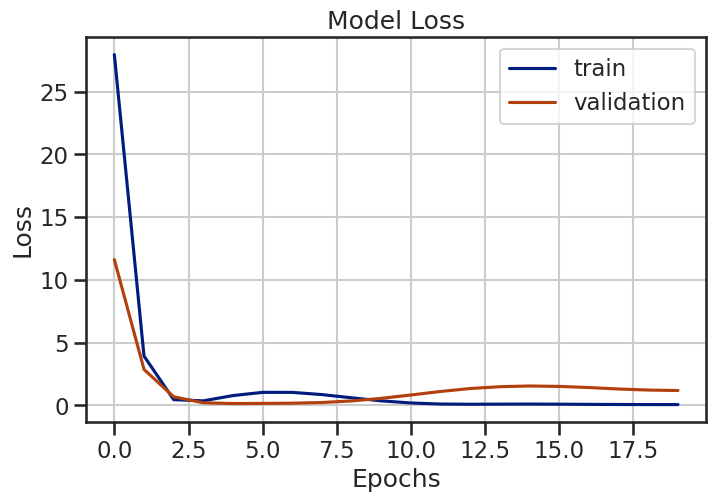

In [ ]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='train'
)

plt.plot(
    history.history['val_loss'],
    label='validation'
)

plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(loc='upper right')
plt.grid(True)

plt.show()

## Final Loss and MSLE

In [ ]:
# Evaluate the ANN model on the test set

score = ann.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Loss: %.5f" % score[0])
print("MSLE: %.5f" % score[1])

Loss: 1.20213
MSLE: 1.20213


Primary forecasting evaluation uses chronological data. Shuffled results are secondary sensitivity analysis only.\n\n## Shuffled ANN Method

In [ ]:
# Use the shuffled split and scaler prepared for the secondary analysis.
print("Training set:", X_train_shuf.shape)
print("Validation set:", X_val_shuf.shape)
print("Testing set:", X_test_shuf.shape)


Training set: (128, 6)
Validation set: (27, 6)
Testing set: (28, 6)


## Form an ANN model with 3 hidden layers

In [ ]:
# Set learning rate
learning_rate_shuffled = 0.01

# Create ANN model with 3 hidden layers
ann_shuffled = Sequential([
    Input(shape=(X_train_shuf.shape[1],)),

    Dense(128, activation='relu'),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),

    Dense(1, activation='linear')
])

## Loss Function and Train the Model

In [ ]:
# Define MSLE loss function
msle_shuffled = MeanSquaredLogarithmicError()

# Compile the ANN model
ann_shuffled.compile(
    loss=msle_shuffled,
    optimizer=Adam(learning_rate=learning_rate_shuffled),
    metrics=[msle_shuffled]
)

# Train the ANN model
history_shuffled = ann_shuffled.fit(
    X_train_shuf,
    y_train_shuf,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_shuf, y_val_shuf),
    verbose=2
)

Epoch 1/20
4/4 - 2s - 489ms/step - loss: 48.2706 - mean_squared_logarithmic_error: 48.2706 - val_loss: 49.1105 - val_mean_squared_logarithmic_error: 49.1105
Epoch 2/20
4/4 - 0s - 23ms/step - loss: 48.2706 - mean_squared_logarithmic_error: 48.2706 - val_loss: 49.1105 - val_mean_squared_logarithmic_error: 49.1105
Epoch 3/20
4/4 - 0s - 22ms/step - loss: 48.2706 - mean_squared_logarithmic_error: 48.2706 - val_loss: 49.1105 - val_mean_squared_logarithmic_error: 49.1105
Epoch 4/20
4/4 - 0s - 22ms/step - loss: 48.2706 - mean_squared_logarithmic_error: 48.2706 - val_loss: 49.1105 - val_mean_squared_logarithmic_error: 49.1105
Epoch 5/20
4/4 - 0s - 23ms/step - loss: 48.2706 - mean_squared_logarithmic_error: 48.2706 - val_loss: 49.1105 - val_mean_squared_logarithmic_error: 49.1105
Epoch 6/20
4/4 - 0s - 27ms/step - loss: 48.2706 - mean_squared_logarithmic_error: 48.2706 - val_loss: 49.1105 - val_mean_squared_logarithmic_error: 49.1105
Epoch 7/20
4/4 - 0s - 23ms/step - loss: 48.2706 - mean_squared_

## Graph of MSLE and Validation MSLE

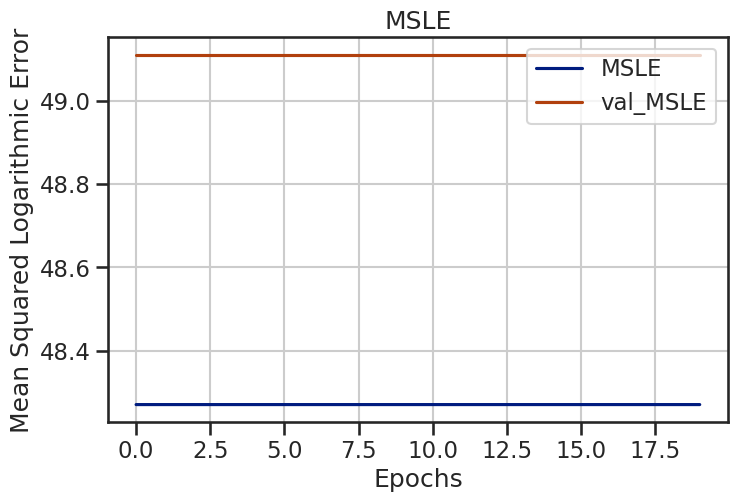

In [ ]:
# Plot MSLE and validation MSLE

plt.figure(figsize=(8, 5))

plt.plot(
    history_shuffled.history['mean_squared_logarithmic_error'],
    label='MSLE'
)

plt.plot(
    history_shuffled.history['val_mean_squared_logarithmic_error'],
    label='val_MSLE'
)

plt.title('MSLE')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Logarithmic Error')
plt.legend(loc='upper right')
plt.grid(True)

plt.show()

## Graph of Predictions and Ground Truth

In [ ]:
# Make predictions using the shuffled ANN model

y_test_pred_shuffled = ann_shuffled.predict(
    X_test_shuf,
    verbose=0
).flatten()

# ICU bed usage cannot be negative
y_test_pred_shuffled = np.clip(
    y_test_pred_shuffled,
    0,
    None
)

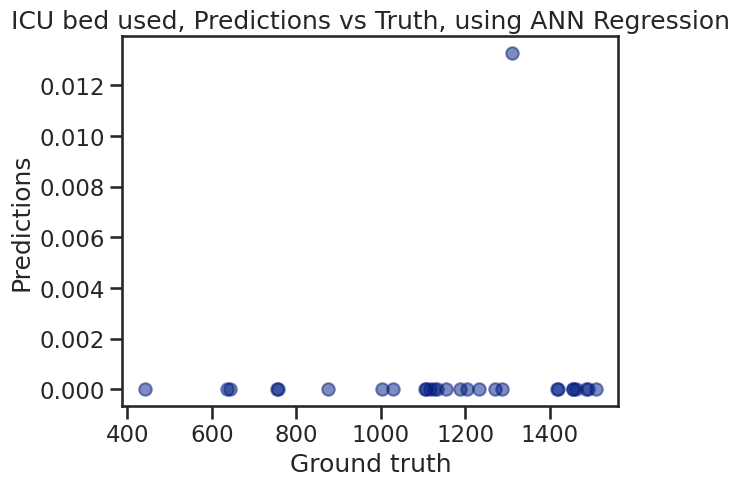

In [ ]:
# Plot Predictions vs Ground Truth

sns.set_context('talk')
sns.set_style('ticks')
sns.set_palette('dark')

ax = plt.axes()

ax.scatter(
    y_test_shuf,
    y_test_pred_shuffled,
    alpha=0.5
)

ax.set(
    xlabel='Ground truth',
    ylabel='Predictions',
    title='ICU bed used, Predictions vs Truth, using ANN Regression'
)

plt.show()

## Evaluate ANN Model

In [ ]:
# Calculate MSLE for training and testing data

train_pred_shuffled = ann_shuffled.predict(
    X_train_shuf,
    verbose=0
).flatten()

train_pred_shuffled = np.clip(
    train_pred_shuffled,
    0,
    None
)

test_pred_shuffled = np.clip(
    y_test_pred_shuffled,
    0,
    None
)

error_df_shuffled = pd.DataFrame({
    'train': [
        mean_squared_log_error(
            y_train_shuf,
            train_pred_shuffled
        )
    ],
    'test': [
        mean_squared_log_error(
            y_test_shuf,
            test_pred_shuffled
        )
    ]
})

error_df_shuffled

,train,test
0,48.27063,49.148735


In [ ]:
# Calculate MSLE for shuffled validation data

val_pred_shuffled = ann_shuffled.predict(
    X_val_shuf,
    verbose=0
).flatten()

val_pred_shuffled = np.clip(
    val_pred_shuffled,
    0,
    None
)

validation_msle_shuffled = mean_squared_log_error(
    y_val_shuf,
    val_pred_shuffled
)

print("Shuffled Validation MSLE:", validation_msle_shuffled)

Shuffled Validation MSLE: 49.11045837402344


## Test Accuracy

In [ ]:
# Calculate R² for the test set

r2_shuffled = r2_score(
    y_test_shuf,
    y_test_pred_shuffled
)

print("R^2:", r2_shuffled)

R^2: -15.927986145019531


## Model Loss

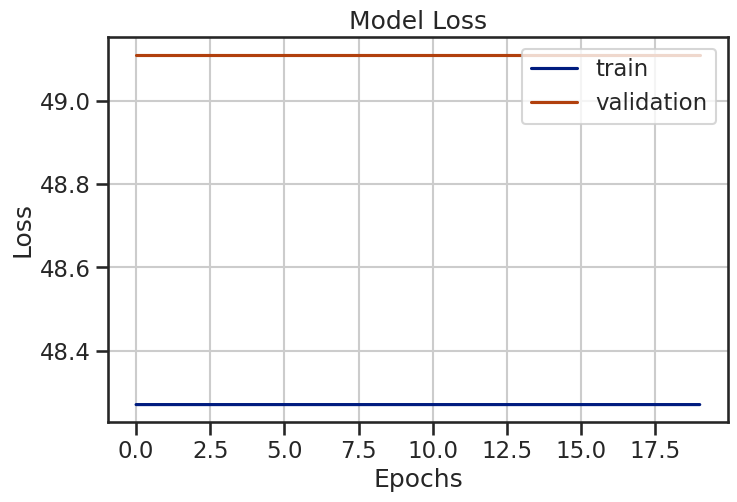

In [ ]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    history_shuffled.history['loss'],
    label='train'
)

plt.plot(
    history_shuffled.history['val_loss'],
    label='validation'
)

plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(loc='upper right')
plt.grid(True)

plt.show()

## Final Loss and MSLE

In [ ]:
# Evaluate the shuffled ANN model on the test set

score_shuffled = ann_shuffled.evaluate(
    X_test_shuf,
    y_test_shuf,
    verbose=0
)

print("Loss: %.5f" % score_shuffled[0])
print("MSLE: %.5f" % score_shuffled[1])

Loss: 49.14874
MSLE: 49.14874


Primary forecasting evaluation uses chronological data. Shuffled results are secondary sensitivity analysis only.\n\n# KNN Regression

In [ ]:
# KNN - UNSHUFFLED

from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_squared_log_error, r2_score
import time

# 1. Tune KNN parameters using validation set
unshuffled_results = []

for k in range(1, 31):
    for weights in ["uniform", "distance"]:
        for p in [1, 2]:
            model = KNeighborsRegressor(n_neighbors=k, weights=weights, p=p)
            model.fit(X_train, y_train)
            val_pred = model.predict(X_val)
            val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

            unshuffled_results.append({
                "K": k,
                "Weights": weights,
                "P": p,
                "Validation_RMSE": val_rmse
            })

# 2. Select the best parameter combination
unshuffled_tuning_df = pd.DataFrame(unshuffled_results).sort_values("Validation_RMSE").reset_index(drop=True)

best_unshuffled = unshuffled_tuning_df.iloc[0]
best_k_unshuffled = int(best_unshuffled["K"])
best_weights_unshuffled = best_unshuffled["Weights"]
best_p_unshuffled = int(best_unshuffled["P"])

print("Best K:", best_k_unshuffled)
print("Best Weights:", best_weights_unshuffled)
print("Best Distance:", "Manhattan" if best_p_unshuffled == 1 else "Euclidean")
print(f"Validation RMSE: {best_unshuffled['Validation_RMSE']:.3f}")

# 3. Combine training and validation sets
X_train_val_unshuffled = np.vstack([np.asarray(X_train), np.asarray(X_val)])
y_train_val_unshuffled = np.concatenate([np.asarray(y_train).ravel(), np.asarray(y_val).ravel()])

# 4. Train the final KNN model
knn_unshuffled = KNeighborsRegressor(n_neighbors=best_k_unshuffled, weights=best_weights_unshuffled, p=best_p_unshuffled)

start_time = time.perf_counter()
knn_unshuffled.fit(X_train_val_unshuffled, y_train_val_unshuffled)
training_time_unshuffled = time.perf_counter() - start_time

# 5. Predict the test set
start_time = time.perf_counter()
X_train_val_unshuffled = pd.concat([X_train, X_val],axis=0)
y_train_val_unshuffled = pd.concat([y_train, y_val],axis=0)
knn_unshuffled.fit(X_train_val_unshuffled,y_train_val_unshuffled)
y_pred_unshuffled = knn_unshuffled.predict(X_test)
prediction_time_unshuffled = time.perf_counter() - start_time

# 6. Evaluate the model
mae_unshuffled = mean_absolute_error(y_test, y_pred_unshuffled)
rmse_unshuffled = np.sqrt(mean_squared_error(y_test, y_pred_unshuffled))
r2_unshuffled = r2_score(y_test, y_pred_unshuffled)

print("\n[UNSHUFFLED KNN RESULTS]")
print(f"MAE:  {mae_unshuffled:.3f}")
print(f"RMSE: {rmse_unshuffled:.3f}")
print(f"R²:   {r2_unshuffled:.6f}")
print(f"Training Time: {training_time_unshuffled:.6f} seconds")
print(f"Prediction Time: {prediction_time_unshuffled:.6f} seconds")


Best K: 1
Best Weights: uniform
Best Distance: Euclidean
Validation RMSE: 196.450

[UNSHUFFLED KNN RESULTS]
MAE:  147.750
RMSE: 166.499
R²:   -2.235247
Training Time: 0.000877 seconds
Prediction Time: 0.004166 seconds


In [ ]:
# Evaluate the final unshuffled KNN model
train_val_pred_unshuffled = knn_unshuffled.predict(
    X_train_val_unshuffled
)

msle_train_val_knn_unshuf = mean_squared_log_error(
    y_train_val_unshuffled,
    np.clip(train_val_pred_unshuffled, 0, None)
)

msle_test_knn_unshuf = mean_squared_log_error(
    y_test,
    np.clip(y_pred_unshuffled, 0, None)
)

print("Unshuffled KNN")
print("Mean Squared Logarithmic Error:")
print(f"Train + Validation: {msle_train_val_knn_unshuf:.6f}")
print(f"Test: {msle_test_knn_unshuf:.6f}")


Unshuffled KNN
Mean Squared Logarithmic Error:
Train: 0.000000
Test: 0.065411
Validation: 0.031388


In [ ]:
# KNN - SHUFFLED

from sklearn.model_selection import train_test_split

# 1. Combine the original train, validation and test sets
X_all_shuffled = np.vstack([np.asarray(X_train), np.asarray(X_val), np.asarray(X_test)])
y_all_shuffled = np.concatenate([np.asarray(y_train).ravel(), np.asarray(y_val).ravel(), np.asarray(y_test).ravel()])

# 2. Split data randomly into 70% training, 15% validation and 15% testing
X_train_shuffled, X_temp_shuffled, y_train_shuffled, y_temp_shuffled = train_test_split(
    X_all_shuffled, y_all_shuffled, test_size=0.30, shuffle=True, random_state=42
)

X_val_shuffled, X_test_shuffled, y_val_shuffled, y_test_shuffled = train_test_split(
    X_temp_shuffled, y_temp_shuffled, test_size=0.50, shuffle=True, random_state=42
)

print("Training:", X_train_shuffled.shape)
print("Validation:", X_val_shuffled.shape)
print("Testing:", X_test_shuffled.shape)

# 3. Tune KNN parameters using validation set
shuffled_results = []

for k in range(1, 31):
    for weights in ["uniform", "distance"]:
        for p in [1, 2]:
            model = KNeighborsRegressor(n_neighbors=k, weights=weights, p=p)
            model.fit(X_train_shuffled, y_train_shuffled)
            val_pred = model.predict(X_val_shuffled)
            val_rmse = np.sqrt(mean_squared_error(y_val_shuffled, val_pred))

            shuffled_results.append({
                "K": k,
                "Weights": weights,
                "P": p,
                "Validation_RMSE": val_rmse
            })

# 4. Select the best parameter combination
shuffled_tuning_df = pd.DataFrame(shuffled_results).sort_values("Validation_RMSE").reset_index(drop=True)

best_shuffled = shuffled_tuning_df.iloc[0]
best_k_shuffled = int(best_shuffled["K"])
best_weights_shuffled = best_shuffled["Weights"]
best_p_shuffled = int(best_shuffled["P"])

print("\nBest K:", best_k_shuffled)
print("Best Weights:", best_weights_shuffled)
print("Best Distance:", "Manhattan" if best_p_shuffled == 1 else "Euclidean")
print(f"Validation RMSE: {best_shuffled['Validation_RMSE']:.3f}")

# 5. Train the best KNN model on training set
knn_best_shuffled = KNeighborsRegressor(n_neighbors=best_k_shuffled, weights=best_weights_shuffled, p=best_p_shuffled)
knn_best_shuffled.fit(X_train_shuffled, y_train_shuffled)

y_train_pred_shuf = knn_best_shuffled.predict(X_train_shuffled)
y_val_pred_shuf = knn_best_shuffled.predict(X_val_shuffled)

# 6. Combine training and validation sets
X_train_val_shuffled = np.vstack([X_train_shuffled, X_val_shuffled])
y_train_val_shuffled = np.concatenate([y_train_shuffled, y_val_shuffled])

# 7. Train the final KNN model
knn_shuffled = KNeighborsRegressor(n_neighbors=best_k_shuffled, weights=best_weights_shuffled, p=best_p_shuffled)

start_time = time.perf_counter()
knn_shuffled.fit(X_train_val_shuffled, y_train_val_shuffled)
training_time_shuffled = time.perf_counter() - start_time

# 8. Predict the test set
start_time = time.perf_counter()
y_pred_shuffled = knn_shuffled.predict(X_test_shuffled)
prediction_time_shuffled = time.perf_counter() - start_time

# 9. Evaluate the model
mae_shuffled = mean_absolute_error(
    y_test_shuffled,
    y_pred_shuffled
)

rmse_shuffled = np.sqrt(
    mean_squared_error(
        y_test_shuffled,
        y_pred_shuffled
    )
)

r2_shuffled = r2_score(
    y_test_shuffled,
    y_pred_shuffled
)

print("\n[SHUFFLED KNN SENSITIVITY RESULTS]")
print(f"MAE:  {mae_shuffled:.3f}")
print(f"RMSE: {rmse_shuffled:.3f}")
print(f"R²:   {r2_shuffled:.6f}")
print(f"Training Time: {training_time_shuffled:.6f} seconds")
print(f"Prediction Time: {prediction_time_shuffled:.6f} seconds")

Training: (128, 6)
Validation: (27, 6)
Testing: (28, 6)

Best K: 5
Best Weights: uniform
Best Distance: Euclidean
Validation RMSE: 39.575

[SHUFFLED KNN RESULTS]
MAE:  63.062
RMSE: 80.752
R²:   0.920795
Training Time: 0.000833 seconds
Prediction Time: 0.000790 seconds


In [ ]:
# Evaluate the final shuffled KNN model
train_val_pred_shuffled = knn_shuffled.predict(
    X_train_val_shuffled
)

msle_train_val_knn_shuf = mean_squared_log_error(
    y_train_val_shuffled,
    np.clip(train_val_pred_shuffled, 0, None)
)

msle_test_knn_shuf = mean_squared_log_error(
    y_test_shuffled,
    np.clip(y_pred_shuffled, 0, None)
)

print("Shuffled KNN Sensitivity Analysis")
print("Mean Squared Logarithmic Error:")
print(f"Train + Validation: {msle_train_val_knn_shuf:.6f}")
print(f"Test: {msle_test_knn_shuf:.6f}")


Shuffled KNN
Mean Squared Logarithmic Error:
Train: 0.002344
Test: 0.003754
Validation: 0.001362


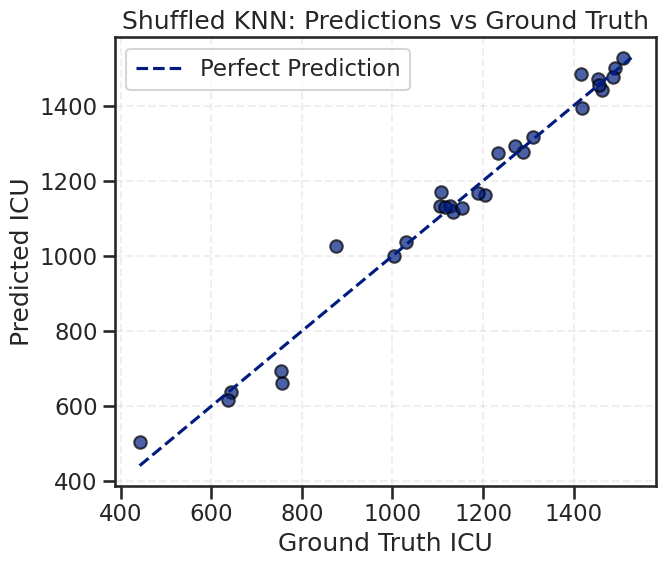

In [ ]:
# 1. Plot shuffled predictions against ground truth
plt.figure(figsize=(7, 6))
plt.scatter(y_test_shuffled, y_pred_shuffled, alpha=0.7, edgecolors="black")

# 2. Add perfect prediction line
minimum = min(np.min(y_test_shuffled), np.min(y_pred_shuffled))
maximum = max(np.max(y_test_shuffled), np.max(y_pred_shuffled))
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--", label="Perfect Prediction")

# 3. Add labels
plt.xlabel("Ground Truth ICU")
plt.ylabel("Predicted ICU")
plt.title("Shuffled KNN: Predictions vs Ground Truth")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

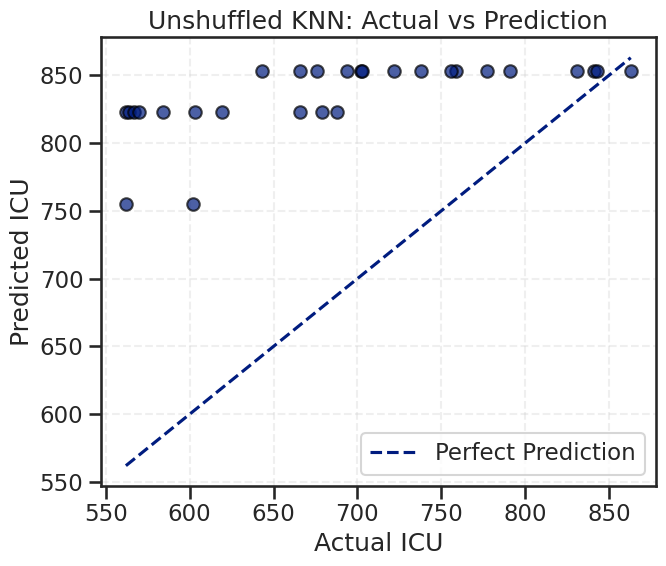

In [ ]:
# 1. Plot unshuffled predictions against actual values
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_unshuffled, alpha=0.7, edgecolors="black")

# 2. Add perfect prediction line
minimum = min(np.min(y_test), np.min(y_pred_unshuffled))
maximum = max(np.max(y_test), np.max(y_pred_unshuffled))
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--", label="Perfect Prediction")

# 3. Add labels
plt.xlabel("Actual ICU")
plt.ylabel("Predicted ICU")
plt.title("Unshuffled KNN: Actual vs Prediction")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Compare unshuffled and shuffled KNN results
comparison = pd.DataFrame({
    "KNN Method": ["Unshuffled", "Shuffled"],
    "Best K": [best_k_unshuffled, best_k_shuffled],
    "Weights": [best_weights_unshuffled, best_weights_shuffled],
    "Distance": ["Manhattan" if best_p_unshuffled == 1 else "Euclidean", "Manhattan" if best_p_shuffled == 1 else "Euclidean"],
    "MAE": [mae_unshuffled, mae_shuffled],
    "RMSE": [rmse_unshuffled, rmse_shuffled],
    "R²": [r2_unshuffled, r2_shuffled]
})

comparison

,KNN Method,Best K,Weights,Distance,MAE,RMSE,R²
0,Unshuffled,1,uniform,Euclidean,147.75000,166.498713,-2.235247
1,Shuffled,5,uniform,Euclidean,63.06165,80.752388,0.920795


# Final Comparison of Four Models

In [ ]:
# Compare the four models on the chronological test set
lasso_mae_final = mean_absolute_error(y_test, y_test_pred_unshuf)
lasso_rmse_final = np.sqrt(mean_squared_error(y_test, y_test_pred_unshuf))

linear_mae_final = mean_absolute_error(y_test, y_test_pred_lr_unshuf)
linear_rmse_final = np.sqrt(mean_squared_error(y_test, y_test_pred_lr_unshuf))

ann_mae_final = mean_absolute_error(y_test, y_test_pred)
ann_rmse_final = np.sqrt(mean_squared_error(y_test, y_test_pred))
ann_msle_final = mean_squared_log_error(y_test, y_test_pred)
ann_r2_final = r2_score(y_test, y_test_pred)

final_model_comparison = pd.DataFrame({
    "Model": [
        "Lasso Regression",
        "Linear Regression",
        "ANN Regression",
        "KNN Regression"
    ],
    "MAE": [
        lasso_mae_final,
        linear_mae_final,
        ann_mae_final,
        mae_unshuffled
    ],
    "RMSE": [
        lasso_rmse_final,
        linear_rmse_final,
        ann_rmse_final,
        rmse_unshuffled
    ],
    "MSLE": [
        msle_test_unshuf,
        msle_test_lr_unshuf,
        ann_msle_final,
        msle_test_knn_unshuf
    ],
    "R²": [
        r2_unshuf,
        r2_lr_unshuf,
        ann_r2_final,
        r2_unshuffled
    ]
})

print("\n================= FINAL MODEL COMPARISON =================")
print("Chronological test-set results:")
final_model_comparison.round(6)

## Shuffled Sensitivity Comparison

In [ ]:
# Compare the four models on the shuffled test set
ann_mae_shuffled = mean_absolute_error(y_test_shuf, y_test_pred_shuffled)
ann_rmse_shuffled = np.sqrt(mean_squared_error(y_test_shuf, y_test_pred_shuffled))
ann_msle_shuffled = mean_squared_log_error(y_test_shuf, y_test_pred_shuffled)
ann_r2_shuffled = r2_score(y_test_shuf, y_test_pred_shuffled)

shuffled_model_comparison = pd.DataFrame({
    "Model": [
        "Lasso Regression",
        "Linear Regression",
        "ANN Regression",
        "KNN Regression"
    ],
    "MAE": [
        mean_absolute_error(y_test_shuf, y_test_pred_shuf),
        mean_absolute_error(y_test_shuf, y_test_pred_lr_shuf),
        ann_mae_shuffled,
        mae_shuffled
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_shuf, y_test_pred_shuf)),
        np.sqrt(mean_squared_error(y_test_shuf, y_test_pred_lr_shuf)),
        ann_rmse_shuffled,
        rmse_shuffled
    ],
    "MSLE": [
        msle_test_shuf,
        msle_test_lr_shuf,
        ann_msle_shuffled,
        msle_test_knn_shuf
    ],
    "R²": [
        r2_shuf,
        r2_lr_shuf,
        ann_r2_shuffled,
        r2_shuffled
    ]
})

print("\n================= SHUFFLED MODEL COMPARISON =================")
print("Shuffled test-set sensitivity results:")
shuffled_model_comparison.round(6)